In [1]:
import pandas as pd
import kagglehub
import os


path = kagglehub.dataset_download("dansbecker/melbourne-housing-snapshot")

print("Path:", path)


print(os.listdir(path))

Path: /kaggle/input/datasets/dansbecker/melbourne-housing-snapshot
['melb_data.csv']


In [2]:
df = pd.read_csv(os.path.join(path, "melb_data.csv"))
print(df.isnull().sum())

Suburb              0
Address             0
Rooms               0
Type                0
Price               0
Method              0
SellerG             0
Date                0
Distance            0
Postcode            0
Bedroom2            0
Bathroom            0
Car                62
Landsize            0
BuildingArea     6450
YearBuilt        5375
CouncilArea      1369
Lattitude           0
Longtitude          0
Regionname          0
Propertycount       0
dtype: int64


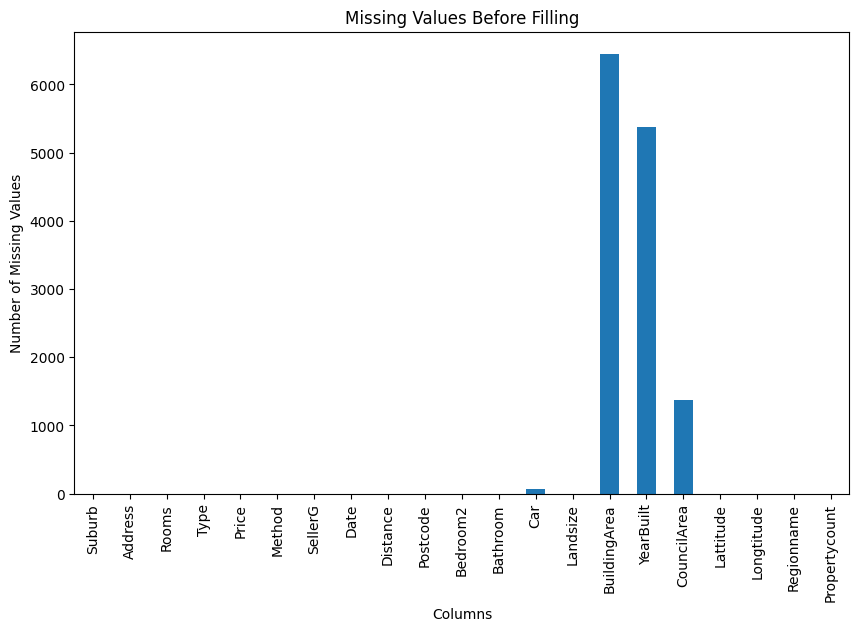

In [3]:
import matplotlib.pyplot as plt

missing = df.isnull().sum()

plt.figure(figsize=(10,6))
missing.plot(kind='bar')
plt.title("Missing Values Before Filling")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=90)
plt.show()

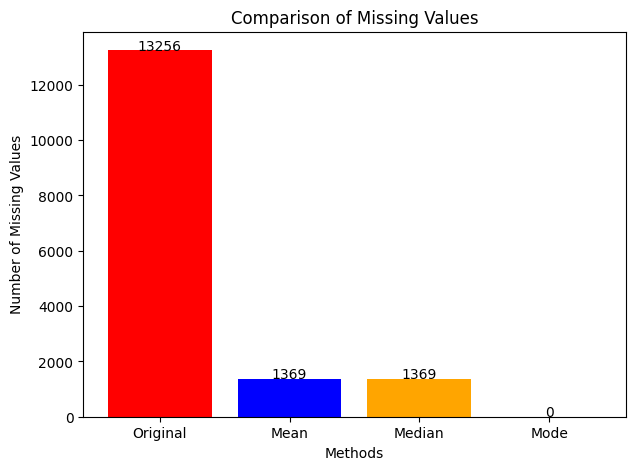

In [4]:
import matplotlib.pyplot as plt

original_missing = df.isnull().sum().sum()

df_mean = df.copy()
df_median = df.copy()
df_mode = df.copy()

numeric_cols = df.select_dtypes(include=['number']).columns

for col in numeric_cols:
    df_mean[col] = df_mean[col].fillna(df_mean[col].mean())

for col in numeric_cols:
    df_median[col] = df_median[col].fillna(df_median[col].median())

for col in df_mode.columns:
    df_mode[col] = df_mode[col].fillna(df_mode[col].mode()[0])

mean_missing = df_mean.isnull().sum().sum()
median_missing = df_median.isnull().sum().sum()
mode_missing = df_mode.isnull().sum().sum()

methods = ['Original', 'Mean', 'Median', 'Mode']
values = [original_missing, mean_missing, median_missing, mode_missing]

plt.figure(figsize=(7,5))
plt.bar(methods, values, color=['red','blue','orange','green'])
plt.title("Comparison of Missing Values")
plt.xlabel("Methods")
plt.ylabel("Number of Missing Values")

for i, v in enumerate(values):
    plt.text(i, v + 5, str(v), ha='center')

plt.show()

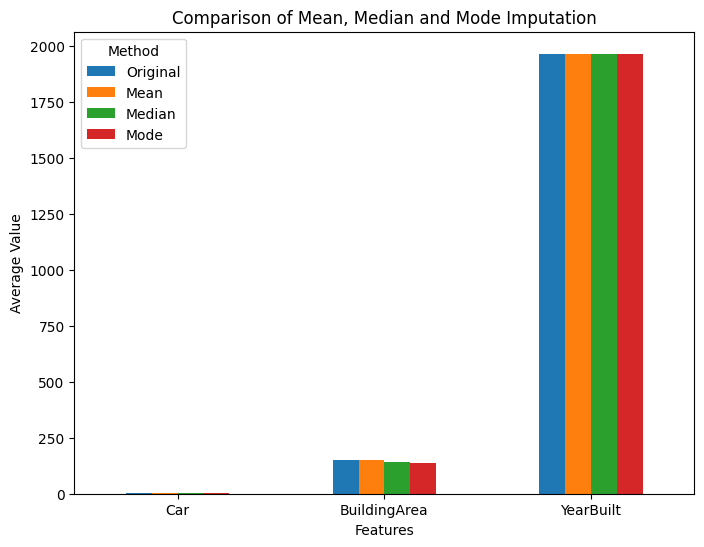

In [5]:
import matplotlib.pyplot as plt

cols = ['Car', 'BuildingArea', 'YearBuilt']

comparison = {
    'Original': df[cols].mean(),
    'Mean': df_mean[cols].mean(),
    'Median': df_median[cols].mean(),
    'Mode': df_mode[cols].mean()
}

comparison_df = pd.DataFrame(comparison)

comparison_df.plot(kind='bar', figsize=(8,6))

plt.title("Comparison of Mean, Median and Mode Imputation")
plt.xlabel("Features")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.legend(title="Method")
plt.show()

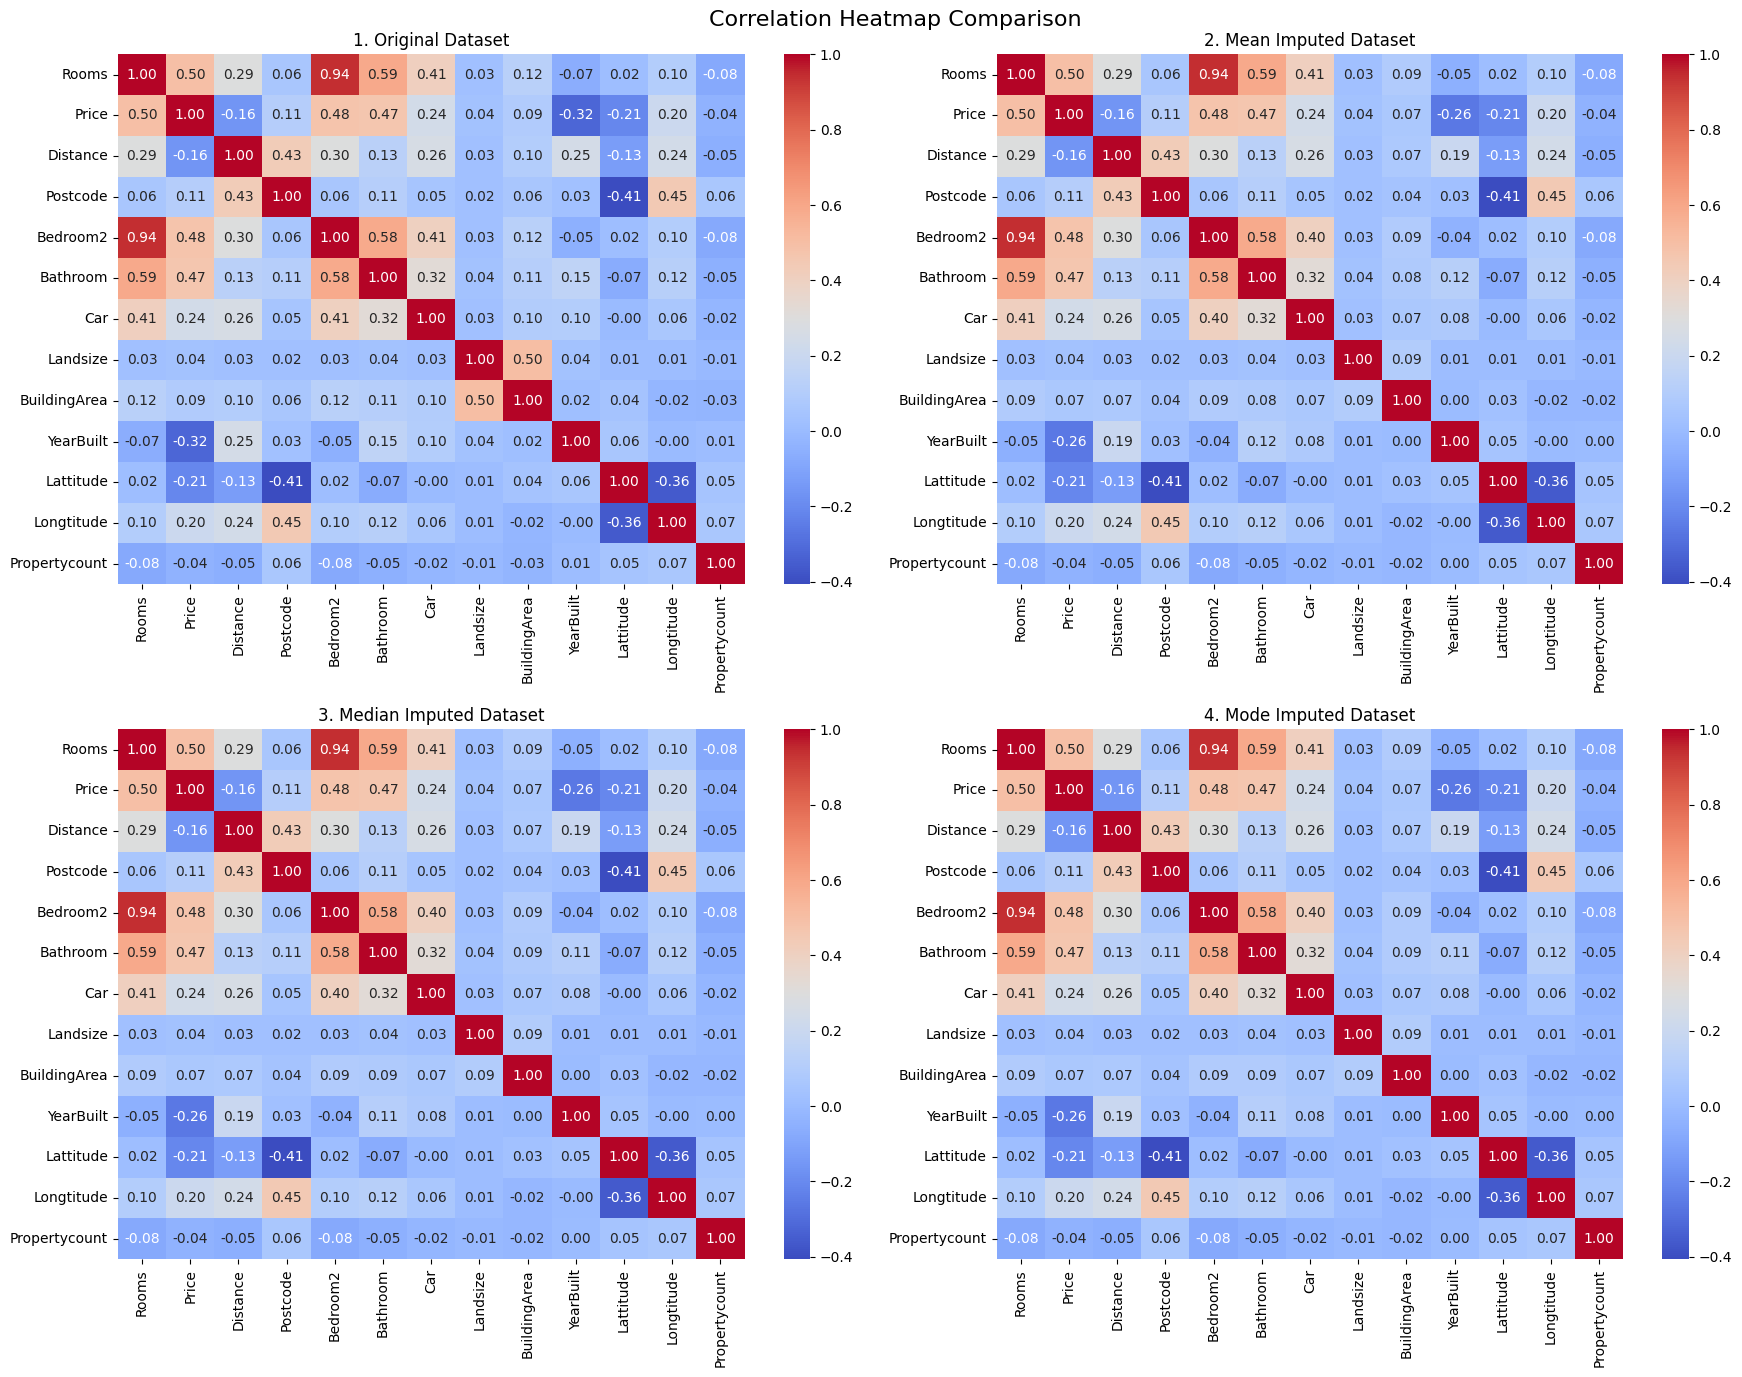

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = df.select_dtypes(include='number').columns

fig, axes = plt.subplots(2, 2, figsize=(18, 14))

sns.heatmap(df[numeric_cols].corr(),
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            ax=axes[0,0])
axes[0,0].set_title("1. Original Dataset")

sns.heatmap(df_mean[numeric_cols].corr(),
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            ax=axes[0,1])
axes[0,1].set_title("2. Mean Imputed Dataset")

sns.heatmap(df_median[numeric_cols].corr(),
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            ax=axes[1,0])
axes[1,0].set_title("3. Median Imputed Dataset")

sns.heatmap(df_mode[numeric_cols].corr(),
            annot=True,
            fmt=".2f",
            cmap="coolwarm",
            ax=axes[1,1])
axes[1,1].set_title("4. Mode Imputed Dataset")

plt.suptitle("Correlation Heatmap Comparison", fontsize=16)
plt.tight_layout()
plt.show()